## Figure 4C


Load the data

In [ ]:
import anndata
from anndata import AnnData
import pandas as pd
import rectanglepy as rp
import matplotlib.pyplot as plt
from scipy.io import mmread
from scipy.sparse import csr_matrix
import helper

import re



In [ ]:
gld = pd.read_excel("../data/fig4/luca_cancer.xlsx", index_col=0)
gld = gld.fillna(0)
gld = gld[gld["Cancer type"] == "BRCA"]

gld = gld.drop(columns=["Unnamed: 7", "Cancer type"])
gld.index = gld.index.str.replace("-", ".")
# Create a new column 'sample_name' that contains the sample names without the last character
gld['sample_name'] = gld.index.str[:-1]

# Group the rows based on the 'sample_name' column and calculate the mean for each group
df_grouped = gld.groupby('sample_name').mean()
#remove CPE = 0
df_grouped = df_grouped[df_grouped['CPE'] != 0]

### Brca data

In [ ]:
# you can find a version of the file under: https://figshare.com/account/articles/32521659
bulks_brca = pd.read_csv("../data/fig4/TCGA_tpm_BRCA.txt", sep="\t")

In [ ]:
pd.Series(bulks_brca.columns)

In [ ]:
ribsosomal_gene_re = r"^RP[SL]|^RP\d|^RPSA"
# remove ribosomal genes from bulk and scRNA-seq data
bulks_brca = bulks_brca[~bulks_brca.index.str.match(ribsosomal_gene_re)]


## Brca rework


In [ ]:
from scipy.io import mmread
from pathlib import Path
import pandas as pd
import scanpy as sc
base = Path("../data/fig4/Wu_etal_2021_BRCA_scRNASeq")
X = mmread(base / "count_matrix_sparse.mtx").tocsr()
barcodes = pd.read_csv(base / "count_matrix_barcodes.tsv", sep="\t", header=None, usecols=[0])[0].astype(str)
genes_df = pd.read_csv(base / "count_matrix_genes.tsv", sep="\t", header=None)
metadata_wu = pd.read_csv(base / "metadata.csv", index_col=0)
gene_names = (genes_df.iloc[:, 1] if genes_df.shape[1] > 1 else genes_df.iloc[:, 0]).astype(str)

In [ ]:
metadata_wu['celltype_minor'].value_counts()

In [ ]:

adata_wu = sc.AnnData(X.T)
adata_wu.obs_names = barcodes.values
adata_wu.var_names = gene_names.values
adata_wu.var_names_make_unique()

def flatten_index(idx):
    return pd.Index([
        x[0] if isinstance(x, tuple) and len(x) == 1 else x
        for x in idx
    ]).astype(str)

adata_wu.obs_names = flatten_index(adata_wu.obs_names)
metadata_wu.index = flatten_index(metadata_wu.index)

adata_wu.obs = adata_wu.obs.join(metadata_wu, how="left")
adata_wu.obs["cell_type_minor"] = adata_wu.obs["celltype_minor"]

excluded_celltypes_wu = {
    "Cycling T-cells",
    "Cycling_Myeloid",
    "Cancer Cycling",
    "Cycling PVL",
    "Myoepithelial",
    "Luminal Progenitors",
    "Mature Luminal",
}
n_before = adata_wu.n_obs
celltypes_before = len(adata_wu.obs["cell_type_minor"].value_counts())
adata_wu = adata_wu[~adata_wu.obs["cell_type_minor"].isin(excluded_celltypes_wu)].copy()
celltypes_after = len(adata_wu.obs["cell_type_minor"].value_counts())
print("cells before:", n_before, "after:", adata_wu.n_obs)
print("celltypes before:", celltypes_before, "after:", celltypes_after)

In [ ]:
adata_wu.obs['cell_type_minor'].value_counts()

In [ ]:
cancer_celltypes_wu = {
    "Cancer Her2 SC",
    "Cancer LumB SC",
    "Cancer Basal SC",
    "Cancer LumA SC"

}
adata_wu_no_cancer = adata_wu[~adata_wu.obs["cell_type_minor"].isin(cancer_celltypes_wu)].copy()
print("celltypes no cancer:", len(adata_wu_no_cancer.obs["cell_type_minor"].value_counts()))

In [ ]:
adata_wu_no_cancer.obs['cell_type_minor'].value_counts()


In [ ]:
wu_estimations, signature_results_wu = rp.rectangle(adata_wu, bulks_brca.T,cell_type_col='cell_type_minor')
wu_estimations.to_csv("../output/wu_estimations.csv")

In [ ]:
import pickle
with open('../output/signature_result_wu.pkl', 'wb') as f:
    pickle.dump(signature_results_wu, f)

### Luad + Lusc data

In [2]:
gld = pd.read_excel("../data/fig4/luca_cancer.xlsx", index_col=0)
gld = gld.fillna(0)
gld = gld.drop(columns=["Unnamed: 7", "Cancer type"])
gld.index = gld.index.str.replace("-", ".")
# Create a new column 'sample_name' that contains the sample names without the last character
gld['sample_name'] = gld.index.str[:-1]

# Group the rows based on the 'sample_name' column and calculate the mean for each group
df_grouped = gld.groupby('sample_name').mean()

df_grouped = df_grouped[df_grouped['CPE'] != 0]

gld.to_csv("./luca_gld.csv")

/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


In [3]:
luad_bulk = pd.read_csv("../data/fig4/luad.csv", index_col=0)
lusc_bulk = pd.read_csv("../data/fig4/lusc.csv", index_col=0)


In [ ]:
pd.Series(lusc_bulk.columns)

In [ ]:

luca_sd = anndata.read_h5ad("../data/fig4/lambrechts.h5ad")

In [ ]:

luca_sd = luca_sd[luca_sd.obs['cell_type'] != 'Epithelial cells']
luca_sd_no_cancer = luca_sd[luca_sd.obs['cell_type'] != 'Tumor cells']

# remove ribosomal genes from bulk is enough since rectangle matches the genes
ribsosomal_gene_re = r"^RP[SL]|^RP\d|^RPSA"
luad_bulk = luad_bulk[~luad_bulk.index.str.match(ribsosomal_gene_re)]
lusc_bulk = lusc_bulk[~lusc_bulk.index.str.match(ribsosomal_gene_re)]


In [ ]:
luca_sd.obs.value_counts()

In [ ]:
luad_estimations, signature_results_luad = rp.rectangle(luca_sd, luad_bulk.T)
luad_estimations.to_csv("../output/luad_estimations.csv")

lusc_estimations, signature_results_lusc = rp.rectangle(luca_sd, lusc_bulk.T)
lusc_estimations.to_csv("../output/lusc_estimations.csv")

In [ ]:
luad_estimations_no_cancer, signature_results_luad_no_cancer = rp.rectangle(luca_sd_no_cancer, luad_bulk.T)
luad_estimations_no_cancer.to_csv("../output/luad_estimations_no_cancer.csv")
lusc_estimations_no_cancer, signature_results_lusc_no_cancer = rp.rectangle(luca_sd_no_cancer, lusc_bulk.T)
lusc_estimations_no_cancer.to_csv("../output/lusc_estimations_no_cancer.csv")

In [ ]:
luad_estimations = pd.read_csv("../output/luad_estimations.csv", index_col=0)
luad_estimations['CPE'] = luad_estimations['Unknown'] + luad_estimations['Tumor cells']
luad_estimations_m, luad_gld_m = helper.match_dfs(luad_estimations, df_grouped)
evaluation_luad = helper.create_evaluation_df(luad_gld_m.T, luad_estimations_m.T)
rsme_luad, r_luad, p_luad = helper.evaulate_total_df(evaluation_luad)

# Just Tumor cells
luad_estimations = pd.read_csv("../output/luad_estimations.csv", index_col
=0)
luad_estimations['CPE'] = luad_estimations['Tumor cells']
luad_estimations_m, luad_gld_m_cancer = helper.match_dfs(luad_estimations, df_grouped)
evaluation_luad_cancer = helper.create_evaluation_df(luad_gld_m_cancer.T, luad_estimations_m.T)
rsme_luad_cancer, r_luad_cancer, p_luad = helper.evaulate_total_df(evaluation_luad_cancer)

# Just Unknown
luad_estimations_no_cancer = pd.read_csv("../output/luad_estimations_no_cancer.csv", index_col=0)
luad_estimations_no_cancer['CPE'] = luad_estimations_no_cancer['Unknown']
luad_estimations_no_cancer_m, luad_gld_m_no_cancer = helper.match_dfs(luad_estimations_no_cancer, df_grouped)
evaluation_luad_no_cancer = helper.create_evaluation_df(luad_gld_m_no_cancer.T, luad_estimations_no_cancer_m.T)
rsme_luad_no_cancer, r_luad_no_cancer, p_luad_no_cancer = helper.evaulate_total_df(evaluation_luad_no_cancer)

# LUSC: Unknown + Tumor cells
lusc_estimations = pd.read_csv("../output/lusc_estimations.csv", index_col=0)
lusc_estimations['CPE'] = lusc_estimations['Unknown'] + lusc_estimations['Tumor cells']
lusc_estimations_m, lusc_gld_m = helper.match_dfs(lusc_estimations, df_grouped)
evaluation_lusc = helper.create_evaluation_df(lusc_gld_m.T, lusc_estimations_m.T)
rsme_lusc, r_lusc, p_lusc = helper.evaulate_total_df(evaluation_lusc)

# LUSC: Just Tumor cells
lusc_estimations = pd.read_csv("../output/lusc_estimations.csv", index_col=0)
lusc_estimations['CPE'] = lusc_estimations['Tumor cells']
lusc_estimations_m, lusc_gld_m_cancer = helper.match_dfs(lusc_estimations, df_grouped)
evaluation_lusc_cancer = helper.create_evaluation_df(lusc_gld_m_cancer.T, lusc_estimations_m.T)
rsme_lusc_cancer, r_lusc_cancer, p_lusc = helper.evaulate_total_df(evaluation_lusc_cancer)

# LUSC: Just Unknown
lusc_estimations_no_cancer = pd.read_csv("../output/lusc_estimations_no_cancer.csv", index_col=0)
lusc_estimations_no_cancer['CPE'] = lusc_estimations_no_cancer['Unknown']
lusc_estimations_no_cancer_m, lusc_gld_m_no_cancer = helper.match_dfs(lusc_estimations_no_cancer, df_grouped)
evaluation_lusc_no_cancer = helper.create_evaluation_df(lusc_gld_m_no_cancer.T, lusc_estimations_no_cancer_m.T)
rsme_lusc_no_cancer, r_lusc_no_cancer, p_lusc_no_cancer = helper.evaulate_total_df(evaluation_lusc_no_cancer)





In [ ]:
(lusc_estimations['Unknown'].sum() + luad_estimations['Unknown'].sum()) / (len(lusc_estimations) + len(luad_estimations))


<Axes: title={'center': 'Tumor+Unkn'}, xlabel='Tumor purity', ylabel='Tumor + unknown cells'>

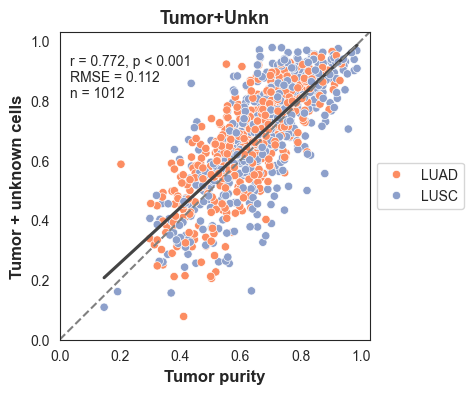

In [4]:

luad_estimations = pd.read_csv("../output/luad_estimations.csv", index_col=0)
luad_estimations['CPE'] = luad_estimations['Unknown'] + luad_estimations['Tumor cells']

lusc_estimations = pd.read_csv("../output/lusc_estimations.csv", index_col=0)
lusc_estimations['CPE'] = lusc_estimations['Unknown'] + lusc_estimations['Tumor cells']

brca_estimations = pd.read_csv("../output/brca_estimations.csv", index_col=0)
brca_estimations.index = brca_estimations.index.str.replace("-", ".")
brca_estimations['CPE'] = brca_estimations['Unknown'] + brca_estimations['Cancer Epithelial']


luad_estimations['data'] = 'LUAD'
lusc_estimations['data'] = 'LUSC'
brca_estimations['data'] = 'BRCA'

all = pd.concat([ luad_estimations, lusc_estimations])

all_m, gld_m = helper.match_dfs(all, df_grouped)

evaluation_all = helper.create_evaluation_df(gld_m.T, all_m.T)

all = all[all.index.isin(all_m.index)]
all = all.loc[all.index].sort_index()
evaluation_all['data'] = all['data'].values

rsme_all, r_all, p_all = helper.evaulate_total_df(evaluation_all)

helper.create_scatter_plot_total(evaluation_all, rsme_all, p_all, r_all, 'Tumor+Unkn', y_axis_label="Tumor + unknown cells", x_axis_label="Tumor purity", hue='data', save_path='../figures/fig4a_all_tumor_and_unkn.pdf', size=(4, 4))

In [ ]:
luad_estimations = pd.read_csv("../output/luad_estimations.csv", index_col=0)
luad_estimations['CPE'] = luad_estimations['Tumor cells']

lusc_estimations = pd.read_csv("../output/lusc_estimations.csv", index_col=0)
lusc_estimations['CPE'] = lusc_estimations['Tumor cells']

brca_estimations = pd.read_csv("../output/brca_estimations.csv", index_col=0)
brca_estimations.index = brca_estimations.index.str.replace("-", ".")
brca_estimations['CPE'] = brca_estimations['Unknown'] + brca_estimations['Cancer Epithelial']

luad_estimations['data'] = 'Luad'
lusc_estimations['data'] = 'Lusc'
brca_estimations['data'] = 'Brca'

all = pd.concat([luad_estimations, lusc_estimations])

all_m, gld_m = helper.match_dfs(all, df_grouped)

evaluation_all = helper.create_evaluation_df(gld_m.T, all_m.T)
all = all[all.index.isin(all_m.index)]
all = all.loc[all.index].sort_index()
evaluation_all['data'] = all['data'].values

rsme_all_t, r_all_t, p_all = helper.evaulate_total_df(evaluation_all)

helper.create_scatter_plot_total(evaluation_all, rsme_all_t, p_all, r_all_t, 'Tumor', y_axis_label="Tumor cells", x_axis_label="Tumor purity", hue='data', save_path='../figures/fig4a_all_tumor.pdf', size=(4, 4))

In [ ]:
#no tumor
luad_estimations_no_cancer = pd.read_csv("../output/luad_estimations_no_cancer.csv", index_col=0)
luad_estimations_no_cancer['CPE'] = luad_estimations_no_cancer['Unknown']
lusc_estimations_no_cancer = pd.read_csv("../output/lusc_estimations_no_cancer.csv", index_col=0)
lusc_estimations_no_cancer['CPE'] = lusc_estimations_no_cancer['Unknown']
brca_estimations_no_cancer = pd.read_csv("../output/brca_estimations_no_cancer.csv", index_col=0)
brca_estimations_no_cancer.index = brca_estimations_no_cancer.index.str.replace("-", ".")
brca_estimations_no_cancer['CPE'] = brca_estimations_no_cancer['Unknown']

luad_estimations_no_cancer['data'] = 'LUAD'
lusc_estimations_no_cancer['data'] = 'LUSC'
brca_estimations_no_cancer['data'] = 'BRCA'


all_no_cancer = pd.concat(
    [ luad_estimations_no_cancer, lusc_estimations_no_cancer],
    axis=0
)
all_no_cancer_m, gld_m_no_cancer = helper.match_dfs(all_no_cancer, df_grouped)
print((all_no_cancer_m.index == gld_m_no_cancer.index).all())
evaluation_all_no_cancer = helper.create_evaluation_df(gld_m_no_cancer.T, all_no_cancer_m.T)
all_no_cancer = all_no_cancer[all_no_cancer.index.isin(all_no_cancer_m.index)]
all_no_cancer_aligned = all_no_cancer.loc[all_no_cancer_m.index].sort_index()
evaluation_all_no_cancer['data'] = all_no_cancer_aligned['data'].values
rsme_all_no_cancer, r_all_no_cancer, p_all_no_cancer = helper.evaulate_total_df(evaluation_all_no_cancer)

helper.create_scatter_plot_total(evaluation_all_no_cancer, rsme_all_no_cancer, p_all_no_cancer, r_all_no_cancer, 'Unknown', y_axis_label="Unknown cells", x_axis_label="Tumor purity", hue='data', save_path='../figures/fig4a_all_unkn.pdf', size=(4, 4))


## 4B

In [ ]:
## 4C

In [6]:
unknown_content_results = pd.read_csv("../data/fig4/unknown_content_results.csv", index_col=0)
distinct_fractions = [0.1 , 0.2 , 0.3 , 0.5 , 0.7 , 0.9 , 0.  ]
unknown_content_results = unknown_content_results[unknown_content_results['unknown_fraction'].isin(distinct_fractions)]

# Rename methods to match method_palette capitalization
method_mapping = {
    'autogenes': 'AutoGeneS',
    'bayesprism': 'BayesPrism',
    'bisque': 'Bisque',
    'cibersortx': 'CIBERSORTx',
    'dwls': 'DWLS',
    'music': 'MuSiC',
    'scaden': 'Scaden',
    'scdc': 'SCDC',
    'rectangle': 'Rectangle'
}
unknown_content_results['method'] = unknown_content_results['method'].replace(method_mapping)

In [7]:
from scipy import stats

# Correlation results grouped by celltype, method, replicate, dataset, unknown_fraction
correlation_results = unknown_content_results.groupby(['celltype', 'method', 'replicate', 'dataset', 'unknown_fraction']).apply(
    lambda x: pd.Series({
        'corr': stats.pearsonr(x['true_value'], x['predicted_value'])[0],
        'pval': stats.pearsonr(x['true_value'], x['predicted_value'])[1]
    })
).reset_index()

# Correlation results for all cells grouped by method, replicate, dataset, unknown_fraction
correlation_results_all = unknown_content_results.groupby(['method', 'replicate', 'dataset', 'unknown_fraction']).apply(
    lambda x: pd.Series({
        'corr': stats.pearsonr(x['true_value'], x['predicted_value'])[0],
        'pval': stats.pearsonr(x['true_value'], x['predicted_value'])[1]
    })
).reset_index()
correlation_results_all['celltype'] = 'all-cells'

# Correlation results for all cells grouped by method, dataset, unknown_fraction (no replicate)
cor_results_all = unknown_content_results.groupby(['method', 'dataset', 'unknown_fraction']).apply(
    lambda x: pd.Series({
        'corr': stats.pearsonr(x['true_value'], x['predicted_value'])[0],
        'pval': stats.pearsonr(x['true_value'], x['predicted_value'])[1]
    })
).reset_index()

# RMSE results grouped by celltype, method, replicate, dataset, unknown_fraction
rmse_results = unknown_content_results.groupby(['celltype', 'method', 'replicate', 'dataset', 'unknown_fraction']).apply(
    lambda x: pd.Series({
        'rmse': ((x['true_value'] - x['predicted_value'])**2).mean()**0.5
    })
).reset_index()

# RMSE results for all cells grouped by method, replicate, dataset, unknown_fraction
rmse_results_all = unknown_content_results.groupby(['method', 'replicate', 'dataset', 'unknown_fraction']).apply(
    lambda x: pd.Series({
        'rmse': ((x['true_value'] - x['predicted_value'])**2).mean()**0.5
    })
).reset_index()
rmse_results_all['celltype'] = 'all-cells'

# Combine RMSE results
rmse_results = pd.concat([rmse_results, rmse_results_all], ignore_index=True)

# Combine correlation results
correlation_results = pd.concat([correlation_results, correlation_results_all], ignore_index=True)

/var/folders/8f/k23cncy95sd_km_vcbbc6dn40000gn/T/ipykernel_7250/3453203749.py:6: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  'corr': stats.pearsonr(x['true_value'], x['predicted_value'])[0],
/var/folders/8f/k23cncy95sd_km_vcbbc6dn40000gn/T/ipykernel_7250/3453203749.py:7: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  'pval': stats.pearsonr(x['true_value'], x['predicted_value'])[1]
/var/folders/8f/k23cncy95sd_km_vcbbc6dn40000gn/T/ipykernel_7250/3453203749.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  correlation_results = unknown_content_results.groupby(['celltype', 'method', 'replicate', 'da

In [8]:
# Summary function (equivalent to R's data_summary)
def data_summary(data, varname, groupnames):
    """
    Calculate mean, sd, and IQR for a variable grouped by specified columns.

    Parameters:
    - data: DataFrame
    - varname: column name to summarize
    - groupnames: list of column names to group by
    """
    summary = data.groupby(groupnames)[varname].agg([
        ('mean', 'mean'),
        ('sd', 'std'),
        ('25%', lambda x: x.quantile(0.25)),
        ('75%', lambda x: x.quantile(0.75))
    ]).reset_index()

    # Rename 'mean' column to the original variable name
    summary = summary.rename(columns={'mean': varname})

    return summary

# Calculate summary statistics for correlation results
correlation_results_summary = data_summary(correlation_results, 'corr', ['celltype', 'method', 'unknown_fraction', 'dataset'])
correlation_summary_all = correlation_results_summary[correlation_results_summary['celltype'] == 'all-cells']

# Calculate summary statistics for RMSE results
rmse_results_summary = data_summary(rmse_results, 'rmse', ['celltype', 'method', 'unknown_fraction', 'dataset'])
rmse_summary_all = rmse_results_summary[rmse_results_summary['celltype'] == 'all-cells']

In [9]:
rmse_summary_all

,celltype,method,unknown_fraction,dataset,rmse,sd,25%,75%
259,all-cells,AutoGeneS,0.0,lambrechts,0.087565,0.003606,0.084398,0.090366
260,all-cells,AutoGeneS,0.1,lambrechts,0.076845,0.003972,0.073764,0.078878
261,all-cells,AutoGeneS,0.2,lambrechts,0.101393,0.008600,0.094553,0.105127
262,all-cells,AutoGeneS,0.3,lambrechts,0.148036,0.022049,0.128231,0.162041
263,all-cells,AutoGeneS,0.5,lambrechts,0.213210,0.022048,0.204522,0.227866
...,...,...,...,...,...,...,...,...
317,all-cells,Scaden,0.2,lambrechts,0.131008,0.002503,0.130740,0.132396
318,all-cells,Scaden,0.3,lambrechts,0.151126,0.006071,0.150407,0.154206
319,all-cells,Scaden,0.5,lambrechts,0.202100,0.003694,0.199711,0.202018
320,all-cells,Scaden,0.7,lambrechts,0.249398,0.005062,0.245835,0.253208


In [10]:
method_palette = {
    "AutoGeneS": "#66C2A5",
    "BayesPrism": "#FC8D62",
    "Bisque": "#8DA0CB",
    "CIBERSORTx": "#E78AC3",
    "DWLS": "#A6D854",
    "MuSiC": "#FFD92F",
    "Scaden": "#E5C494",
    "SCDC": "#B3B3B3",
    "Rectangle": "#000000"
}

In [11]:
rmse_summary_all

,celltype,method,unknown_fraction,dataset,rmse,sd,25%,75%
259,all-cells,AutoGeneS,0.0,lambrechts,0.087565,0.003606,0.084398,0.090366
260,all-cells,AutoGeneS,0.1,lambrechts,0.076845,0.003972,0.073764,0.078878
261,all-cells,AutoGeneS,0.2,lambrechts,0.101393,0.008600,0.094553,0.105127
262,all-cells,AutoGeneS,0.3,lambrechts,0.148036,0.022049,0.128231,0.162041
263,all-cells,AutoGeneS,0.5,lambrechts,0.213210,0.022048,0.204522,0.227866
...,...,...,...,...,...,...,...,...
317,all-cells,Scaden,0.2,lambrechts,0.131008,0.002503,0.130740,0.132396
318,all-cells,Scaden,0.3,lambrechts,0.151126,0.006071,0.150407,0.154206
319,all-cells,Scaden,0.5,lambrechts,0.202100,0.003694,0.199711,0.202018
320,all-cells,Scaden,0.7,lambrechts,0.249398,0.005062,0.245835,0.253208


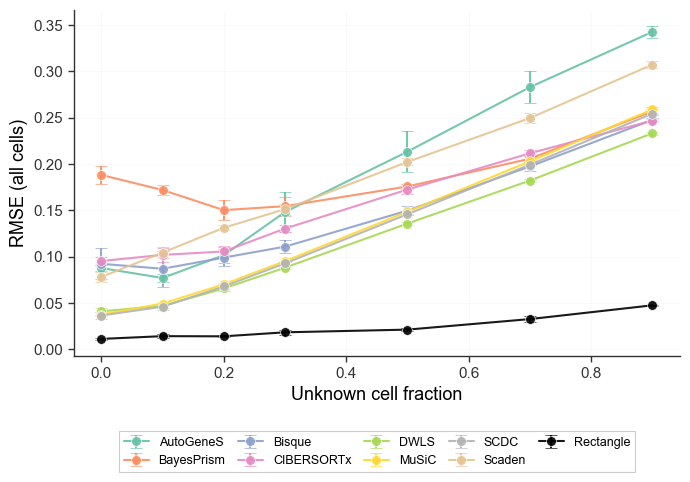

In [12]:
# Plot RMSE summary for all cells
import seaborn as sns
import matplotlib.pyplot as plt

# set theme
sns.set_style("white")
# Modern scientific styling
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']
plt.rcParams['pdf.fonttype'] = 42  # TrueType fonts for better PDF compatibility

fig, ax = plt.subplots(figsize=(7, 5))
ax.set_facecolor('white')
fig.patch.set_facecolor('white')

# Sort methods: alphabetically, but Rectangle last
methods = sorted(rmse_summary_all['method'].unique())
if 'Rectangle' in methods:
    methods.remove('Rectangle')
    methods.append('Rectangle')

# Plot with error bars (using standard deviation)
for method in methods:
    method_data = rmse_summary_all[rmse_summary_all['method'] == method]

    # Sort by unknown_fraction for proper line plotting
    method_data = method_data.sort_values('unknown_fraction')

    x = method_data['unknown_fraction']
    y = method_data['rmse']
    yerr = method_data['sd']

    color = method_palette.get(method, '#000000')
    ax.errorbar(x, y, yerr=yerr, label=method, marker='o', capsize=4,
                capthick=1.5, linewidth=1.5, markersize=7, markeredgewidth=0.5,
                markeredgecolor='white', color=color, alpha=0.9, zorder=3)

ax.set_xlabel('Unknown cell fraction', fontsize=13, fontweight='normal', color='black')
ax.set_ylabel('RMSE (all cells)', fontsize=13, fontweight='normal', color='black')

# Modern legend styling - horizontal layout
legend = ax.legend(bbox_to_anchor=(0.5, -0.2), loc='upper center',
                   frameon=True, fontsize=9, ncol=5,
                   framealpha=1.0, fancybox=False, columnspacing=1.0)
legend.get_frame().set_linewidth(0.8)
legend.get_frame().set_edgecolor('#CCCCCC')
legend.get_frame().set_facecolor('white')
# Ensure legend text is visible
for text in legend.get_texts():
    text.set_color('black')

# Subtle grid
ax.grid(True, alpha=0.15, linestyle='-', linewidth=0.5, color='#CCCCCC', zorder=1)
ax.set_axisbelow(True)

# Clean spines
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
for spine in ['left', 'bottom']:
    ax.spines[spine].set_color('#333333')
    ax.spines[spine].set_linewidth(1)

# Enable minor ticks
ax.minorticks_on()

# Tick styling - major ticks
ax.tick_params(axis='both', which='major', labelsize=11,
               length=4, width=1, colors='#333333',
               top=False, right=False, bottom=True, left=True,
               labeltop=False, labelright=False, labelbottom=True, labelleft=True)


plt.tight_layout()
plt.savefig('../figures/fig4c_rmse_summary_all.pdf', bbox_inches='tight', dpi=300)
plt.show()


In [ ]:
# Plot Correlation summary for all cells
fig, ax = plt.subplots(figsize=(7, 5))
ax.set_facecolor('white')
fig.patch.set_facecolor('white')

# Sort methods: alphabetically, but Rectangle last
methods = sorted(correlation_summary_all['method'].unique())
if 'Rectangle' in methods:
    methods.remove('Rectangle')
    methods.append('Rectangle')

# Plot with error bars (using standard deviation)
for method in methods:
    method_data = correlation_summary_all[correlation_summary_all['method'] == method]

    # Sort by unknown_fraction for proper line plotting
    method_data = method_data.sort_values('unknown_fraction')

    x = method_data['unknown_fraction']
    y = method_data['corr']
    yerr = method_data['sd']

    color = method_palette.get(method, '#000000')
    ax.errorbar(x, y, yerr=yerr, label=method, marker='o', capsize=4,
                capthick=1.5, linewidth=1.5, markersize=7, markeredgewidth=0.5,
                markeredgecolor='white', color=color, alpha=0.9, zorder=3)

ax.set_xlabel('Unknown cell fraction', fontsize=13, fontweight='normal', color='black')
ax.set_ylabel('Correlation (all cells)', fontsize=13, fontweight='normal', color='black')

# Modern legend styling - horizontal layout
legend = ax.legend(bbox_to_anchor=(0.5, -0.2), loc='upper center',
                   frameon=True, fontsize=9, ncol=5,
                   framealpha=1.0, fancybox=False, columnspacing=1.0)
legend.get_frame().set_linewidth(0.8)
legend.get_frame().set_edgecolor('#CCCCCC')
legend.get_frame().set_facecolor('white')
# Ensure legend text is visible
for text in legend.get_texts():
    text.set_color('black')

# Subtle grid
ax.grid(True, alpha=0.15, linestyle='-', linewidth=0.5, color='#CCCCCC', zorder=1)
ax.set_axisbelow(True)

ax.set_ylim([-0.3, 1.05])

# Clean spines
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
for spine in ['left', 'bottom']:
    ax.spines[spine].set_color('#333333')
    ax.spines[spine].set_linewidth(1)

# Enable minor ticks
ax.minorticks_on()

# Tick styling - major ticks
ax.tick_params(axis='both', which='major', labelsize=11,
               length=4, width=1, colors='#333333',
               top=False, right=False, bottom=True, left=True,
               labeltop=False, labelright=False, labelbottom=True, labelleft=True)


plt.tight_layout()
plt.savefig('../figures/fig4c_correlation_summary_all.pdf', bbox_inches='tight', dpi=300)
plt.show()


# MRNA BIAS

In [ ]:
adata_hao_sub = anndata.read_h5ad('../data/haoSub_adata.h5ad')
sc_data_muris = pd.read_pickle("../data/sc_data_tabula_muris.pkl")
annotations = pd.read_csv("../data/annotations_tabula_muris.csv", index_col=0)
annotations = annotations['0']
annotations = pd.Series(annotations, index=sc_data_muris.columns)
adata_muris = AnnData(sc_data_muris.T, obs=annotations.to_frame(name="cell_type"))

bulks_chen = pd.read_csv("../data/bulks_chen_tpm.csv", index_col=0)
bulks_peti = pd.read_csv("../data/bulks_petitprez_tpm.csv", index_col=0)
bulks_fino = pd.read_csv("../data/fig2/finotello/bulks_finotello_tpm.csv", index_col=0)
bulks_hoek = pd.read_csv("../data/bulks_hoek_tpm.csv", index_col=0)
bulks_morandini = pd.read_csv("../data/fig2/morandini/morandini_tpm.csv.gz", index_col=0)
bulks_altman = pd.read_csv("../data/fig2/altman/altman_tpm.csv.gz", index_col=0)
bulks_dietrich = pd.read_csv("../data/fig2/deconvME/dietrich_tpm.csv", index_col=0)



In [ ]:
estimations_fino_no_bias, signature_results_fino_no_bias = rp.rectangle(adata_hao_sub, bulks_fino.T, correct_mrna_bias=False)
estimations_fino_no_bias.to_csv("../output/estimations_fino_no_bias.csv")


In [ ]:
estimations_fino_no_bias = pd.read_csv("../output/estimations_fino_no_bias.csv", index_col=0)

In [ ]:
finotello_gld = pd.read_csv('../data/finotello_facs.csv', index_col=0).T
finotello_gld = finotello_gld.fillna(0)
finotello_gld.columns = ["NK cells", 'B cells', 'Tregs', 'mDC', 'Monocytes', 'Neutrophilss', 'T cells CD8',
                         'T cells CD4 conv', 'Other']
finotello_gld = finotello_gld.T
gld_m, finotello_m = helper.match_dfs(finotello_gld, estimations_fino_no_bias.T)
gld_m = gld_m.sort_index(key=lambda x: x.str.lower())
finotello_m = finotello_m.sort_index(key=lambda x: x.str.lower())
evaluation_fintotello_rectangle = helper.create_evaluation_df(gld_m, finotello_m)
rsme_finotello_rectangle, r_finotello_rectangle, p_finotello_rectangle = helper.evaulate_total_df(
    evaluation_fintotello_rectangle)
rsmes_f_rectangle, ps_f_rectangle, rs_f_rectangle = helper.evaluate_by_cell_type(gld_m, finotello_m)
helper.create_scatter_plot_total(evaluation_fintotello_rectangle, rsme_finotello_rectangle, p_finotello_rectangle,
                                 r_finotello_rectangle,
                                 'Finotello', save_path='../figures/fig4_fino_no_bias.pdf', size=(3, 3))

In [ ]:
estimations_hoek_no_bias, signature_results_hoek_no_bias = rp.rectangle(adata_hao_sub, bulks_hoek.T, correct_mrna_bias=False)
estimations_hoek_no_bias.to_csv("../output/estimations_hoek_no_bias.csv")


In [ ]:
estimations_hoek = pd.read_csv("../output/estimations_hoek_no_bias.csv", index_col=0)

In [ ]:
hoek_gld = pd.read_csv('../data/hoek_facs.csv', index_col=0).T
hoek_gld = hoek_gld.fillna(0)
hoek_gld.columns = ["T cells", 'Monocytes', 'B cells', 'mDC', 'NK cells']
hoek_gld = hoek_gld.T


estimations_hoek['T cells'] = estimations_hoek['T cells CD4 conv'] + estimations_hoek['T cells CD8'] + estimations_hoek[
    'Tregs']

estimations_hoek = estimations_hoek.T

gld_hoek_m, hoek_m = helper.match_dfs(hoek_gld, estimations_hoek)
gld_hoek_m = gld_hoek_m.sort_index(key=lambda x: x.str.lower())
hoek_m = hoek_m.sort_index(key=lambda x: x.str.lower())
evaluation_hoek = helper.create_evaluation_df(gld_hoek_m, hoek_m)
rsme_hoek, r_hoek, p_hoek = helper.evaulate_total_df(evaluation_hoek)
rsmes_h, ps_h, rs_h = helper.evaluate_by_cell_type(gld_hoek_m, hoek_m)
helper.create_scatter_plot_total(evaluation_hoek, rsme_hoek, p_hoek, r_hoek, 'Hoek', save_path='../figures/fig2a_hoek_no_bias.pdf', size=(3, 3))

In [ ]:
estimations_chen_no_bias, signature_results_chen_no_bias = rp.rectangle(adata_muris, bulks_chen.T, correct_mrna_bias=False)
estimations_chen_no_bias.to_csv("../output/estimations_chen_no_bias.csv")

In [ ]:
estimations_chen = pd.read_csv("../output/estimations_chen_no_bias.csv", index_col=0)

In [ ]:
chen_gld = pd.read_csv('../data/chen_facs.csv', index_col=0).T
chen_gld = chen_gld.fillna(0)
chen_gld.columns = ["Monocytes", "B cells", 'T cells CD8', 'T cells CD4 Total']
chen_t = estimations_chen
chen_t['T cells CD4 Total'] = chen_t['T cells CD4 conv'] + chen_t['Tregs']
chen_m, gld_m = helper.match_dfs(chen_t,chen_gld)
# sort alphabetically reverse
gld_m = gld_m.sort_index(key=lambda x: x.str.lower(), ascending=True)
chen_m = chen_m.sort_index(key=lambda x: x.str.lower(), ascending=True)
evaluation_chen = helper.create_evaluation_df(gld_m.T, chen_m.T)
# sort by index alphabetically ignore case
evaluation_chen = evaluation_chen.sort_values(by='Cell type', key=lambda x: x.str.lower())
rsme_chen, r_chen, p_chen = helper.evaulate_total_df(evaluation_chen)
rsmes_chen, ps_chen, rs_chen = helper.evaluate_by_cell_type(gld_m.T, chen_m.T)

helper.create_scatter_plot_total(evaluation_chen, rsme_chen, p_chen, r_chen, 'Chen', save_path='../figures/fig2a_chen_no_bias.pdf', size=(3, 3))

In [ ]:
estimations_peti_no_bias, signature_results_peti_no_bias = rp.rectangle(adata_muris, bulks_peti.T, correct_mrna_bias=False)
estimations_peti_no_bias.to_csv("../output/estimations_peti_no_bias.csv")

In [ ]:
estimations_peti = pd.read_csv("../output/estimations_peti_no_bias.csv", index_col=0)

In [ ]:
petitprez_gld = pd.read_csv('../data/petitprez_facs.csv', index_col=0).T
petitprez_gld = petitprez_gld.fillna(0)

# replace nan with 0
petitprez_gld = petitprez_gld.fillna(0)

petitprez_gld.columns = ["T cells", 'T cells CD8', 'B cells', 'Tregs', 'NK cells', 'B cells ger', 'Basophils', 'Mast',
                         'Macrophages', 'Eosinophils', 'Neutrophils', 'Monocytes', 'B derived', 'Mono Macro', 'NK_or_T',
                         'Granulocytes']
# drop columns
petitprez_gld = petitprez_gld.drop(['T cells'], axis=1)

# sort by index alphabetically ignore case
petitprez_gld = petitprez_gld.sort_index(key=lambda x: x.str.lower())
estimations_peti = estimations_peti.sort_index(key=lambda x: x.str.lower())


gld_m, petitprez_m = helper.match_dfs(petitprez_gld, estimations_peti)
evaluation_petitprez = helper.create_evaluation_df(gld_m.T, petitprez_m.T)
# sort by index alphabetically ignore case
evaluation_petitprez = evaluation_petitprez.sort_values(by='Cell type', key=lambda x: x.str.lower())
rsme_peptirez, r_peptirez, p_peptirez = helper.evaulate_total_df(evaluation_petitprez)
rsmes_pept, ps_pept, rs_pept = helper.evaluate_by_cell_type(gld_m.T, petitprez_m.T)

helper.create_scatter_plot_total(evaluation_petitprez, rsme_peptirez, p_peptirez, r_peptirez, 'Petitprez',
                                 save_path='../figures/fig2a_petitprez_no_bias.pdf', size=(3, 3))


In [ ]:
estimations_morandini_no_bias, signature_results_morandini_no_bias = rp.rectangle(adata_hao_sub, bulks_morandini.T, correct_mrna_bias=False)
estimations_morandini_no_bias.to_csv("../output/estimations_morandini_no_bias.csv")

In [ ]:
estimations_morandini = pd.read_csv("../output/estimations_morandini_no_bias.csv", index_col=0)

In [ ]:
estimations_morandini['T cells CD4'] = estimations_morandini['T cells CD4 conv']
estimations_morandini['T cells'] = estimations_morandini['T cells CD4 conv'] + estimations_morandini['T cells CD8'] + \
                                   estimations_morandini[
                                       'Tregs']
estimations_morandini['Lymphocytes'] = estimations_morandini['T cells'] + estimations_morandini['NK cells'] + \
                                       estimations_morandini['ILC'] + estimations_morandini['B cells'] + \
                                       estimations_morandini['Plasma cells']
estimations_morandini['Monocytes'] = estimations_morandini['Monocytes'] + estimations_morandini['pDC'] + \
                                     estimations_morandini['mDC']
estimations_morandini = estimations_morandini.T
morandini_facs = pd.read_csv('../data/fig2/morandini/morandini_facs.csv', index_col=0)
morandini_facs = morandini_facs.T

gld_m, morandini_m = helper.match_dfs(morandini_facs.T, estimations_morandini)

gld_m = gld_m.sort_index(key=lambda x: x.str.lower())
morandini_m = morandini_m.sort_index(key=lambda x: x.str.lower())
evaluation_morandini = helper.create_evaluation_df(gld_m, morandini_m)
rsme_morandini, r_morandini, p_morandini = helper.evaulate_total_df(evaluation_morandini)
rsmes_morandini, ps_morandini, rs_morandini = helper.evaluate_by_cell_type(gld_m, morandini_m)
helper.create_scatter_plot_total(evaluation_morandini, rsme_morandini, p_morandini, r_morandini,
                                 'Morandini', save_path='../figures/fig2a_morandini_no_bias.pdf', size=(3, 3))

In [ ]:
estimations_altman_no_bias, signature_results_altman_no_bias = rp.rectangle(adata_hao_sub, bulks_altman.T, correct_mrna_bias=False)
estimations_altman_no_bias.to_csv("../output/estimations_altman_no_bias.csv")

In [ ]:
estimations_altman = pd.read_csv("../output/estimations_altman_no_bias.csv", index_col=0)

In [ ]:
estimations_altman['Lymphocytes'] = estimations_altman['T cells CD4 conv'] + estimations_altman['T cells CD8'] + \
                                    estimations_altman[
                                        'Tregs'] + estimations_altman['B cells'] + estimations_altman['NK cells'] + \
                                    estimations_altman['ILC']
estimations_altman['Plasma cells'] = estimations_altman['Lymphocytes'] + estimations_altman['Plasma cells']
estimations_altman['Monocytes'] = estimations_altman['Monocytes'] + estimations_altman['mDC'] + estimations_altman[
    'pDC']
estimations_altman = estimations_altman.T
altman_facs = pd.read_csv('../data/fig2/altman/altman_facs.csv', index_col=0)
altman_facs = altman_facs.T
gld_m, altman_m = helper.match_dfs(altman_facs.T, estimations_altman)
gld_m = gld_m.sort_index(key=lambda x: x.str.lower())
altman_m = altman_m.sort_index(key=lambda x: x.str.lower())
evaluation_altman = helper.create_evaluation_df(gld_m, altman_m)
rsme_altman, r_altman, p_altman = helper.evaulate_total_df(evaluation_altman)
rsmes_altman, ps_altman, rs_altman = helper.evaluate_by_cell_type(gld_m, altman_m)
helper.create_scatter_plot_total(evaluation_altman, rsme_altman, p_altman, r_altman,
                                 'Altman', save_path='../figures/fig2a_altman_no_bias.pdf', size=(3, 3))

In [ ]:
estimations_altman_no_bias, signature_results_altman_no_bias = rp.rectangle(adata_hao_sub, bulks_altman.T, correct_mrna_bias=False)
estimations_altman_no_bias.to_csv("../output/estimations_altman_no_bias.csv")

In [ ]:
estimations_altman = pd.read_csv("../output/estimations_altman_no_bias.csv", index_col=0)

In [ ]:
estimations_altman['Lymphocytes'] = estimations_altman['T cells CD4 conv'] + estimations_altman['T cells CD8'] + \
                                    estimations_altman[
                                        'Tregs'] + estimations_altman['B cells'] + estimations_altman['NK cells'] + \
                                    estimations_altman['ILC']
estimations_altman['Plasma cells'] = estimations_altman['Lymphocytes'] + estimations_altman['Plasma cells']
estimations_altman['Monocytes'] = estimations_altman['Monocytes'] + estimations_altman['mDC'] + estimations_altman[
    'pDC']
estimations_altman = estimations_altman.T
altman_facs = pd.read_csv('../data/fig2/altman/altman_facs.csv', index_col=0)
altman_facs = altman_facs.T
gld_m, altman_m = helper.match_dfs(altman_facs.T, estimations_altman)
gld_m = gld_m.sort_index(key=lambda x: x.str.lower())
altman_m = altman_m.sort_index(key=lambda x: x.str.lower())
evaluation_altman = helper.create_evaluation_df(gld_m, altman_m)
rsme_altman, r_altman, p_altman = helper.evaulate_total_df(evaluation_altman)
rsmes_altman, ps_altman, rs_altman = helper.evaluate_by_cell_type(gld_m, altman_m)
helper.create_scatter_plot_total(evaluation_altman, rsme_altman, p_altman, r_altman,
                                 'Altman', save_path='../figures/fig2a_altman_no_bias.pdf', size=(3, 3))

In [ ]:
estimations_dietrich_no_bias, signature_results_dietrich_no_bias = rp.rectangle(adata_hao_sub, bulks_dietrich.T, correct_mrna_bias=False)
estimations_dietrich_no_bias.to_csv("../output/estimations_dietrich_no_bias.csv")

In [ ]:
estimations_dietrich_no_bias = pd.read_csv("../output/estimations_dietrich_no_bias.csv", index_col=0)

In [ ]:
dietrich_facs = pd.read_csv('../data/fig2/deconvMe/dietrich_facs.csv', index_col=0)
dietrich_facs = dietrich_facs[dietrich_facs.index != 'T cells']

gld_m, dietrich_m = helper.match_dfs(dietrich_facs, estimations_dietrich_no_bias.T)
gld_m = gld_m.sort_index(key=lambda x: x.str.lower())
dietrich_m = dietrich_m.sort_index(key=lambda x: x.str.lower())

evaluation_dietrich = helper.create_evaluation_df(gld_m, dietrich_m)
rsme_dietrich, r_dietrich, p_dietrich = helper.evaulate_total_df(evaluation_dietrich)
rsmes_dietrich, ps_dietrich, rs_dietrich = helper.evaluate_by_cell_type(gld_m, dietrich_m)
helper.create_scatter_plot_total(evaluation_dietrich, rsme_dietrich, p_dietrich, r_dietrich,
                                 'Dietrich', save_path='../figures/fig4_dietrich_no_bias.pdf', size=(3, 3))

## mRNA bias correction comparison


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
import helper

sns.set_style('white')
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'

bulk_order = ['finotello', 'petitprez', 'chen', 'hoek', 'morandini', 'dietrich']
bulk_labels = {
    'finotello': 'Finotello',
    'petitprez': 'Petitprez',
    'chen': 'Chen',
    'hoek': 'Hoek',
    'morandini': 'Morandini',
    'dietrich': 'Dietrich',
}
method_order = ['rectangle', 'rectangle_no_mrna']
method_labels = {
    'rectangle': 'Rectangle',
    'rectangle_no_mrna': 'Rectangle-no-mRNA',
}
cell_type_rename = {
    'T cells CD8': 'CD8 T cells',
    'T cells CD4 conv': 'CD4 T cells',
    'T cells CD4': 'CD4 T cells',
    'T cells CD4 Total': 'CD4 T cells',
    'Neutrophilss': 'Neutrophils',
}


def _normalise_cell_type(cell_type):
    return cell_type_rename.get(str(cell_type), str(cell_type))


def _add_metric_rows(rows, bulk, method, gold, estimated):
    gold = gold.sort_index(key=lambda x: x.str.lower())
    estimated = estimated.sort_index(key=lambda x: x.str.lower())
    evaluation = helper.create_evaluation_df(gold, estimated)
    rmse_total, r_total, _ = helper.evaulate_total_df(evaluation)
    rows.append({
        'cell_type': 'all',
        'method': method,
        'bulk_ds': bulk,
        'cor': float(r_total),
        'RMSE': float(rmse_total),
    })

    rsmes, _, rs = helper.evaluate_by_cell_type(gold, estimated)
    for cell_type, cor_val, rmse_val in zip(gold.index, rs, rsmes):
        rows.append({
            'cell_type': _normalise_cell_type(cell_type),
            'method': method,
            'bulk_ds': bulk,
            'cor': float(cor_val),
            'RMSE': float(rmse_val),
        })


def _load_rectangle_fig2_metrics():
    metrics = pd.read_csv('../data/fig2/cell_type_level_performance_metrics.csv')
    metrics['method'] = metrics['method'].str.lower()
    metrics['bulk_ds'] = metrics['bulk_ds'].str.lower()
    metrics = metrics[(metrics['method'] == 'rectangle') & metrics['bulk_ds'].isin(bulk_order)].copy()
    metrics['cell_type'] = metrics['cell_type'].map(_normalise_cell_type)
    metrics = metrics[['cell_type', 'method', 'bulk_ds', 'cor', 'RMSE']]

    overall = pd.read_csv('../data/cor_rmse_all.csv', sep=';')
    overall.columns = [c.strip() for c in overall.columns]
    overall['method'] = overall['Method'].astype(str).str.strip().str.lower()
    overall['bulk_ds'] = overall['Set'].astype(str).str.strip().str.lower()
    overall = overall[(overall['method'] == 'rectangle') & overall['bulk_ds'].isin(bulk_order)].copy()
    overall['cor'] = overall['Cor'].astype(str).str.replace(',', '.', regex=False).str.strip().astype(float)
    overall['RMSE'] = overall['RMSE'].astype(str).str.replace(',', '.', regex=False).str.strip().astype(float)
    overall['cell_type'] = 'all'
    overall = overall[['cell_type', 'method', 'bulk_ds', 'cor', 'RMSE']]

    rows = pd.concat([metrics, overall], ignore_index=True)

    # Fig 2 stores deconvME/Dietrich cell-level metrics in the metrics CSV, but the
    # overall value is produced locally from hao_estimations_dietrich.csv.
    dietrich_est = pd.read_csv('../output/hao_estimations_dietrich.csv', index_col=0)
    dietrich_facs = pd.read_csv('../data/fig2/deconvMe/dietrich_facs.csv', index_col=0)
    dietrich_facs = dietrich_facs[dietrich_facs.index != 'T cells']
    gld_m, method_m = helper.match_dfs(dietrich_facs, dietrich_est.T)
    gld_m = gld_m.sort_index(key=lambda x: x.str.lower())
    method_m = method_m.sort_index(key=lambda x: x.str.lower())
    evaluation = helper.create_evaluation_df(gld_m, method_m)
    rmse_dietrich, r_dietrich, _ = helper.evaulate_total_df(evaluation)
    rows = rows[~((rows['bulk_ds'] == 'dietrich') & (rows['cell_type'] == 'all'))].copy()
    rows = pd.concat([
        rows,
        pd.DataFrame([{
            'cell_type': 'all',
            'method': 'rectangle',
            'bulk_ds': 'dietrich',
            'cor': float(r_dietrich),
            'RMSE': float(rmse_dietrich),
        }])
    ], ignore_index=True)
    return rows


def _load_no_mrna_metrics():
    rows = []

    finotello_gld = pd.read_csv('../data/finotello_facs.csv', index_col=0).T.fillna(0)
    finotello_gld.columns = ['NK cells', 'B cells', 'Tregs', 'mDC', 'Monocytes', 'Neutrophilss', 'T cells CD8',
                             'T cells CD4 conv', 'Other']
    finotello_gld = finotello_gld.T
    estimations_fino = pd.read_csv('../output/estimations_fino_no_bias.csv', index_col=0)
    gold, estimated = helper.match_dfs(finotello_gld, estimations_fino.T)
    _add_metric_rows(rows, 'finotello', 'rectangle_no_mrna', gold, estimated)

    petitprez_gld = pd.read_csv('../data/petitprez_facs.csv', index_col=0).T.fillna(0)
    petitprez_gld.columns = ['T cells', 'T cells CD8', 'B cells', 'Tregs', 'NK cells', 'B cells ger', 'Basophils', 'Mast',
                             'Macrophages', 'Eosinophils', 'Neutrophils', 'Monocytes', 'B derived', 'Mono Macro', 'NK_or_T',
                             'Granulocytes']
    petitprez_gld = petitprez_gld.drop(['T cells'], axis=1)
    estimations_peti = pd.read_csv('../output/estimations_peti_no_bias.csv', index_col=0)
    estimated, gold = helper.match_dfs(estimations_peti, petitprez_gld)
    _add_metric_rows(rows, 'petitprez', 'rectangle_no_mrna', gold.T, estimated.T)

    chen_gld = pd.read_csv('../data/chen_facs.csv', index_col=0).T.fillna(0)
    chen_gld.columns = ['Monocytes', 'B cells', 'T cells CD8', 'T cells CD4 Total']
    estimations_chen = pd.read_csv('../output/estimations_chen_no_bias.csv', index_col=0)
    estimations_chen['T cells CD4 Total'] = estimations_chen['T cells CD4 conv'] + estimations_chen['Tregs']
    estimated, gold = helper.match_dfs(estimations_chen, chen_gld)
    _add_metric_rows(rows, 'chen', 'rectangle_no_mrna', gold.T, estimated.T)

    hoek_gld = pd.read_csv('../data/hoek_facs.csv', index_col=0).T.fillna(0)
    hoek_gld.columns = ['T cells', 'Monocytes', 'B cells', 'mDC', 'NK cells']
    hoek_gld = hoek_gld.T
    estimations_hoek = pd.read_csv('../output/estimations_hoek_no_bias.csv', index_col=0)
    estimations_hoek['T cells'] = estimations_hoek['T cells CD4 conv'] + estimations_hoek['T cells CD8'] + estimations_hoek['Tregs']
    gold, estimated = helper.match_dfs(hoek_gld, estimations_hoek.T)
    _add_metric_rows(rows, 'hoek', 'rectangle_no_mrna', gold, estimated)

    morandini_facs = pd.read_csv('../data/fig2/morandini/morandini_facs.csv', index_col=0).T
    estimations_morandini = pd.read_csv('../output/estimations_morandini_no_bias.csv', index_col=0)
    estimations_morandini['T cells CD4'] = estimations_morandini['T cells CD4 conv']
    estimations_morandini['T cells'] = estimations_morandini['T cells CD4 conv'] + estimations_morandini['T cells CD8'] + estimations_morandini['Tregs']
    estimations_morandini['Lymphocytes'] = estimations_morandini['T cells'] + estimations_morandini['NK cells'] + estimations_morandini['ILC'] + estimations_morandini['B cells'] + estimations_morandini['Plasma cells']
    estimations_morandini['Monocytes'] = estimations_morandini['Monocytes'] + estimations_morandini['pDC'] + estimations_morandini['mDC']
    gold, estimated = helper.match_dfs(morandini_facs.T, estimations_morandini.T)
    _add_metric_rows(rows, 'morandini', 'rectangle_no_mrna', gold, estimated)

    dietrich_facs = pd.read_csv('../data/fig2/deconvMe/dietrich_facs.csv', index_col=0)
    dietrich_facs = dietrich_facs[dietrich_facs.index != 'T cells']
    estimations_dietrich = pd.read_csv('../output/estimations_dietrich_no_bias.csv', index_col=0)
    gold, estimated = helper.match_dfs(dietrich_facs, estimations_dietrich.T)
    _add_metric_rows(rows, 'dietrich', 'rectangle_no_mrna', gold, estimated)

    return pd.DataFrame(rows)


mrna_bias_metrics = pd.concat([
    _load_rectangle_fig2_metrics(),
    _load_no_mrna_metrics(),
], ignore_index=True)

cell_type_order = sorted([ct for ct in mrna_bias_metrics['cell_type'].dropna().unique() if ct != 'all']) + ['all']
palette = dict(zip(cell_type_order, sns.color_palette('tab20', n_colors=len(cell_type_order))))
palette['all'] = '#111111'

plot_specs = [
    ('cor', 'Correlation', '../figures/fig4_mrna_bias_correction_correlation.pdf'),
    ('RMSE', 'RMSE', '../figures/fig4_mrna_bias_correction_rmse.pdf'),
]

for metric_col, y_label, out_path in plot_specs:
    fig, axes = plt.subplots(2, 3, figsize=(5.4, 4.8), sharey=True, facecolor='white')
    axes = axes.reshape(-1)

    if metric_col == 'cor':
        y_lim = (-0.55, 1.05)
        y_ticks = list(np.linspace(-0.55, 1, 5))
        y_tick_labels = [f'{v:.1f}' if v != 0 else '0' for v in y_ticks]
    else:
        metric_max = float(mrna_bias_metrics[metric_col].max(skipna=True))
        y_lim = (0, max(metric_max * 1.12, 0.1))
        y_ticks = list(np.linspace(0, y_lim[1], 5))
        y_tick_labels = [f'{v:.2f}' for v in y_ticks]

    for ax, bulk in zip(axes, bulk_order):
        ax.set_facecolor('white')
        sub = mrna_bias_metrics[mrna_bias_metrics['bulk_ds'] == bulk]

        for ct in cell_type_order:
            d_ct = sub[sub['cell_type'] == ct]
            if d_ct.empty:
                continue
            x_vals = np.array([method_order.index(m) for m in d_ct['method']], dtype=int)
            y_vals = d_ct[metric_col]
            marker_style = '^' if ct == 'all' else 'o'
            marker_size = 62 if ct == 'all' else 42
            face_color = 'none' if ct == 'all' else palette[ct]
            edge_color = '#111111' if ct == 'all' else 'white'
            line_width = 1.2 if ct == 'all' else 0.5

            if metric_col == 'cor':
                valid_mask = y_vals.notna().to_numpy()
                if valid_mask.any():
                    ax.scatter(
                        x_vals[valid_mask],
                        y_vals.to_numpy()[valid_mask],
                        s=marker_size,
                        marker=marker_style,
                        facecolors=face_color,
                        edgecolors=edge_color,
                        linewidths=line_width,
                        zorder=3,
                    )
                if (~valid_mask).any():
                    nan_y = y_lim[0] + 0.03
                    nan_marker_color = '#111111' if ct == 'all' else palette[ct]
                    ax.scatter(
                        x_vals[~valid_mask],
                        np.full((~valid_mask).sum(), nan_y, dtype=float),
                        s=30,
                        marker='x',
                        color=nan_marker_color,
                        linewidths=1.1,
                        zorder=4,
                    )
            else:
                ax.scatter(
                    x_vals,
                    y_vals,
                    s=marker_size,
                    marker=marker_style,
                    facecolors=face_color,
                    edgecolors=edge_color,
                    linewidths=line_width,
                    zorder=3,
                )

        if metric_col == 'cor':
            ax.axhline(0, linestyle='--', color='lightgrey', linewidth=0.8, zorder=1)
        ax.set_title(bulk_labels[bulk], fontsize=11, weight='bold')
        ax.set_xlim(-0.18, len(method_order) - 0.82)
        ax.set_ylim(*y_lim)
        ax.set_xticks(range(len(method_order)))
        ax.set_xticklabels(['bias\ncorrection', 'no bias\ncorrection'], rotation=0, ha='center')
        ax.tick_params(axis='x', labelsize=8, pad=1)
        ax.grid(axis='y', linestyle=':', alpha=0.35)

    for ax in axes:
        ax.set_yticks(y_ticks)
        ax.set_yticklabels(y_tick_labels)

    fig.text(0.04, 0.5, y_label, va='center', rotation='vertical', fontsize=11)
    legend_handles = [
        Line2D([0], [0], marker='^', linestyle='None', markerfacecolor='none', markeredgecolor='#111111', markersize=8, label='all') if ct == 'all'
        else Line2D([0], [0], marker='o', linestyle='None', markerfacecolor=palette[ct], markeredgecolor='white', markersize=7, label=ct)
        for ct in cell_type_order
    ]
    if metric_col == 'cor':
        legend_handles.append(
            Line2D([0], [0], marker='x', linestyle='None', color='#555555', markersize=7, label='absent cell')
        )
    legend_ncol = 5 if len(legend_handles) > 8 else 4
    fig.legend(handles=legend_handles, loc='upper center', bbox_to_anchor=(0.53, -0.01), ncol=legend_ncol, frameon=False)
    plt.tight_layout(rect=[0.06, 0.12, 1.0, 1.0], w_pad=0.05, h_pad=0.8)
    plt.savefig(out_path, facecolor='white', bbox_inches='tight')
    plt.show()

mrna_bias_metrics



## RMSE reduction with mRNA bias correction


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if 'mrna_bias_metrics' not in globals():
    missing_helpers = [name for name in ['_load_rectangle_fig2_metrics', '_load_no_mrna_metrics'] if name not in globals()]
    if missing_helpers:
        raise NameError(f"Run the mRNA bias correction comparison cell first. Missing: {missing_helpers}")
    mrna_bias_metrics = pd.concat([
        _load_rectangle_fig2_metrics(),
        _load_no_mrna_metrics(),
    ], ignore_index=True)

rmse_change = (
    mrna_bias_metrics
    .pivot_table(index=['bulk_ds', 'cell_type'], columns='method', values='RMSE', aggfunc='mean')
    .reset_index()
)
# Absolute RMSE improvement from applying mRNA bias correction.
rmse_change['rmse_difference'] = rmse_change['rectangle_no_mrna'] - rmse_change['rectangle']
rmse_change = rmse_change.replace([np.inf, -np.inf], np.nan).dropna(subset=['rmse_difference'])
rmse_change['cell_type_label'] = rmse_change['cell_type'].replace({'all': 'All'})
rmse_change['dataset_label'] = rmse_change['bulk_ds'].map(bulk_labels)

dataset_colors = dict(zip(bulk_order, ['#4C78A8', '#F58518', '#54A24B', '#B279A2', '#E45756', '#72B7B2']))

celltype_change = rmse_change.copy()

fig, ax_cells = plt.subplots(figsize=(10.0, 4.8), facecolor='white')

x_pos, heights, labels, bar_colors = [], [], [], []
dataset_ranges = {}
pos = 0
for bulk in bulk_order:
    sub = celltype_change[celltype_change['bulk_ds'] == bulk].copy()
    sub['is_all'] = sub['cell_type'].ne('all')
    sub = sub.sort_values(['is_all', 'rmse_difference'])
    start = pos
    for _, row in sub.iterrows():
        x_pos.append(pos)
        heights.append(float(row['rmse_difference']))
        labels.append(row['cell_type_label'])
        bar_colors.append(dataset_colors[bulk])
        pos += 1
    dataset_ranges[bulk] = (start, pos - 1)
    pos += 1

ax_cells.bar(x_pos, heights, color=bar_colors, alpha=0.9)
ax_cells.axhline(0, color='#444444', linewidth=0.8)
ax_cells.set_xticks(x_pos)
ax_cells.set_xticklabels(labels, rotation=55, ha='right', fontsize=7)
ax_cells.set_ylabel('RMSE difference\n(no correction - correction)')
ax_cells.grid(axis='y', linestyle=':', alpha=0.35)
for spine in ax_cells.spines.values():
    spine.set_linewidth(0.8)

for bulk, (start, end) in dataset_ranges.items():
    if start <= end:
        center = (start + end) / 2
        ax_cells.text(center, 1.03, bulk_labels[bulk], transform=ax_cells.get_xaxis_transform(),
                      ha='center', va='bottom', fontsize=8, fontweight='bold')
        ax_cells.axvline(end + 0.5, color='#DDDDDD', linewidth=0.8)

all_values = np.array(heights, dtype=float)
finite_values = all_values[np.isfinite(all_values)]
if finite_values.size:
    max_abs = max(abs(float(finite_values.min())), abs(float(finite_values.max())), 0.02)
    ax_cells.set_ylim(-max_abs * 0.20, max_abs * 1.20)

fig.suptitle('RMSE difference with mRNA bias correction', fontsize=12, fontweight='bold', y=0.995)
fig.text(0.99, 0.98, 'positive = lower RMSE with bias correction', ha='right', va='top', fontsize=8)
plt.tight_layout(rect=[0.0, 0.0, 1.0, 0.95])
plt.savefig('../figures/fig4_mrna_bias_rmse_reduction.pdf', dpi=300, bbox_inches='tight')
plt.show()

rmse_change



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if 'rmse_change' not in globals():
    raise NameError('Run the RMSE difference cell first to create `rmse_change`.')

overall_rmse = rmse_change[rmse_change['cell_type'] == 'all'].copy()
overall_rmse = overall_rmse.dropna(subset=['rmse_difference'])
if overall_rmse.empty:
    raise ValueError('No overall (cell_type == "all") RMSE rows found.')

overall_rmse['bulk_ds'] = pd.Categorical(overall_rmse['bulk_ds'], categories=bulk_order, ordered=True)
overall_rmse = overall_rmse.sort_values('bulk_ds')

dataset_colors = dict(zip(bulk_order, ['#4C78A8', '#F58518', '#54A24B', '#B279A2', '#E45756', '#72B7B2']))
bar_colors = [dataset_colors[b] for b in overall_rmse['bulk_ds'].astype(str)]
x_labels = [bulk_labels[b] for b in overall_rmse['bulk_ds'].astype(str)]
heights = overall_rmse['rmse_difference'].astype(float).to_list()

fig, ax = plt.subplots(figsize=(6.8, 3.8), facecolor='white')
x = np.arange(len(heights))
bars = ax.bar(x, heights, color=bar_colors, alpha=0.9)
ax.axhline(0, color='#444444', linewidth=0.8)
for bar, h in zip(bars, heights):
    va = 'bottom' if h >= 0 else 'top'
    offset = 0.003 if h >= 0 else -0.003
    ax.text(bar.get_x() + bar.get_width() / 2, h + offset,
            f'{h:.3f}', ha='center', va=va, fontsize=12, color='#222222')
ax.set_xticks(x)
ax.set_xticklabels(x_labels, rotation=30, ha='right', fontsize=12)
ax.set_ylabel('RMSE difference\n(no correction - correction)', fontsize=12)
ax.grid(axis='y', linestyle=':', alpha=0.35)
ax.tick_params(axis='y', labelsize=12)
for spine in ax.spines.values():
    spine.set_linewidth(0.8)

finite_values = np.array(heights, dtype=float)
finite_values = finite_values[np.isfinite(finite_values)]
if finite_values.size:
    max_abs = max(abs(float(finite_values.min())), abs(float(finite_values.max())), 0.02)
    ax.set_ylim(-max_abs * 0.30, max_abs * 1.35)

plt.tight_layout(rect=[0.0, 0.0, 1.0, 0.94])
plt.savefig('../figures/fig4_mrna_bias_rmse_overall_difference.pdf', dpi=300, bbox_inches='tight')
plt.show()

overall_rmse[['bulk_ds', 'rmse_difference']]


## Correlation change with mRNA bias correction


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if 'mrna_bias_metrics' not in globals():
    missing_helpers = [name for name in ['_load_rectangle_fig2_metrics', '_load_no_mrna_metrics'] if name not in globals()]
    if missing_helpers:
        raise NameError(f"Run the mRNA bias correction comparison cell first. Missing: {missing_helpers}")
    mrna_bias_metrics = pd.concat([
        _load_rectangle_fig2_metrics(),
        _load_no_mrna_metrics(),
    ], ignore_index=True)

cor_change = (
    mrna_bias_metrics
    .pivot_table(index=['bulk_ds', 'cell_type'], columns='method', values='cor', aggfunc='mean')
    .reset_index()
)
cor_change['correlation_change'] = cor_change['rectangle'] - cor_change['rectangle_no_mrna']
cor_change = cor_change.replace([np.inf, -np.inf], np.nan).dropna(subset=['correlation_change'])
cor_change['cell_type_label'] = cor_change['cell_type'].replace({'all': 'All'})
cor_change['dataset_label'] = cor_change['bulk_ds'].map(bulk_labels)

dataset_colors = dict(zip(bulk_order, ['#4C78A8', '#F58518', '#54A24B', '#B279A2', '#E45756', '#72B7B2']))

celltype_change = cor_change.copy()

fig, ax_cells = plt.subplots(figsize=(10.0, 4.8), facecolor='white')

x_pos, heights, labels, bar_colors = [], [], [], []
dataset_ranges = {}
pos = 0
for bulk in bulk_order:
    sub = celltype_change[celltype_change['bulk_ds'] == bulk].copy()
    sub['is_all'] = sub['cell_type'].ne('all')
    sub = sub.sort_values(['is_all', 'correlation_change'])
    start = pos
    for _, row in sub.iterrows():
        x_pos.append(pos)
        heights.append(float(row['correlation_change']))
        labels.append(row['cell_type_label'])
        bar_colors.append(dataset_colors[bulk])
        pos += 1
    dataset_ranges[bulk] = (start, pos - 1)
    pos += 1

ax_cells.bar(x_pos, heights, color=bar_colors, alpha=0.9)
ax_cells.axhline(0, color='#444444', linewidth=0.8)
ax_cells.set_xticks(x_pos)
ax_cells.set_xticklabels(labels, rotation=55, ha='right', fontsize=7)
ax_cells.set_ylabel('Correlation difference\n(correction - no correction)')
ax_cells.grid(axis='y', linestyle=':', alpha=0.35)
for spine in ax_cells.spines.values():
    spine.set_linewidth(0.8)

for bulk, (start, end) in dataset_ranges.items():
    if start <= end:
        center = (start + end) / 2
        ax_cells.text(center, 1.03, bulk_labels[bulk], transform=ax_cells.get_xaxis_transform(),
                      ha='center', va='bottom', fontsize=8, fontweight='bold')
        ax_cells.axvline(end + 0.5, color='#DDDDDD', linewidth=0.8)

all_values = np.array(heights, dtype=float)
finite_values = all_values[np.isfinite(all_values)]
if finite_values.size:
    max_abs = max(abs(float(finite_values.min())), abs(float(finite_values.max())), 0.05)
    ax_cells.set_ylim(-max_abs * 0.20, max_abs * 1.20)

fig.suptitle('Correlation difference with mRNA bias correction', fontsize=12, fontweight='bold', y=0.995)
fig.text(0.99, 0.98, 'positive = higher correlation with bias correction', ha='right', va='top', fontsize=8)
plt.tight_layout(rect=[0.0, 0.0, 1.0, 0.95])
plt.savefig('../figures/fig4_mrna_bias_correlation_change.pdf', dpi=300, bbox_inches='tight')
plt.show()

cor_change



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if 'cor_change' not in globals():
    raise NameError('Run the correlation difference cell first to create `cor_change`.')

overall_cor = cor_change[cor_change['cell_type'] == 'all'].copy()
overall_cor = overall_cor.dropna(subset=['correlation_change'])
if overall_cor.empty:
    raise ValueError('No overall (cell_type == "all") correlation rows found.')

overall_cor['bulk_ds'] = pd.Categorical(overall_cor['bulk_ds'], categories=bulk_order, ordered=True)
overall_cor = overall_cor.sort_values('bulk_ds')

dataset_colors = dict(zip(bulk_order, ['#4C78A8', '#F58518', '#54A24B', '#B279A2', '#E45756', '#72B7B2']))
bar_colors = [dataset_colors[b] for b in overall_cor['bulk_ds'].astype(str)]
x_labels = [bulk_labels[b] for b in overall_cor['bulk_ds'].astype(str)]
heights = overall_cor['correlation_change'].astype(float).to_list()

fig, ax = plt.subplots(figsize=(6.8, 3.8), facecolor='white')
x = np.arange(len(heights))
bars = ax.bar(x, heights, color=bar_colors, alpha=0.9)
ax.axhline(0, color='#444444', linewidth=0.8)
for bar, h in zip(bars, heights):
    va = 'bottom' if h >= 0 else 'top'
    offset = 0.002 if h >= 0 else -0.002
    ax.text(bar.get_x() + bar.get_width() / 2, h + offset,
            f'{h:.3f}', ha='center', va=va, fontsize=12, color='#222222')
ax.set_xticks(x)
ax.set_xticklabels(x_labels, rotation=30, ha='right', fontsize=12)
ax.set_ylabel('Correlation difference\n(correction - no correction)', fontsize=12)
ax.grid(axis='y', linestyle=':', alpha=0.35)
ax.tick_params(axis='y', labelsize=12)

for spine in ax.spines.values():
    spine.set_linewidth(0.8)

finite_values = np.array(heights, dtype=float)
finite_values = finite_values[np.isfinite(finite_values)]
if finite_values.size:
    max_abs = max(abs(float(finite_values.min())), abs(float(finite_values.max())), 0.05)
    ax.set_ylim(-max_abs * 0.35, max_abs * 1.35)

plt.tight_layout(rect=[0.0, 0.0, 1.0, 0.94])
plt.savefig('../figures/fig4_mrna_bias_correlation_overall_change.pdf', dpi=300, bbox_inches='tight')
plt.show()

overall_cor[['bulk_ds', 'correlation_change']]
